<a href="https://colab.research.google.com/github/Henrietta-quarshie7/Elevvo_internshp_models/blob/main/Movie_Recommendation_system.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

. Project objectives
A recommendation system that suggests movies to users based on the preferences of other users with similar ratings.

Our project will:
1. Load and explore the MovieLens 100K dataset.
2. Clean and preprocess the data.
3. Create a user-item rating matrix.
4. Calculate user similarity using cosine similarity.
5. Recommend movies that a user has not watched.
6. Evaluate recommendations using Precision at K.
7. Test recommendations for a selected user.
2. Tools and libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab
- GitHub
3. Project workflow
1. Import libraries and load dataset
2. Explore and clean the dataset
3. Split ratings into training and testing data
4. Create the user-item matrix
5. Calculate user similarity
6. Generate movie recommendations
7. Evaluate using Precision at K
8. Test recommendations for an individual user

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset downloading
import urllib.request
import zipfile
import os

# Machine learning
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

# Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Dataset URL
url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"

# Download dataset
urllib.request.urlretrieve(url, "ml-100k.zip")

# Extract dataset
with zipfile.ZipFile("ml-100k.zip", "r") as zip_ref:
    zip_ref.extractall(".")

print("Dataset downloaded and extracted successfully!")

Dataset downloaded and extracted successfully!


In [3]:
# Load ratings dataset
ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=["user_id", "movie_id", "rating", "timestamp"]
)

# Load movie information
movies = pd.read_csv(
    "ml-100k/u.item",
    sep="|",
    encoding="latin-1",
    usecols=[0, 1],
    names=["movie_id", "title"],
    header=None
)

# Merge ratings with movie titles
df = pd.merge(ratings, movies, on="movie_id")

# Display first five records
df.head()

,user_id,movie_id,rating,timestamp,title
0,196,242,3,881250949,Kolya (1996)
1,186,302,3,891717742,L.A. Confidential (1997)
2,22,377,1,878887116,Heavyweights (1994)
3,244,51,2,880606923,Legends of the Fall (1994)
4,166,346,1,886397596,Jackie Brown (1997)


In [4]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 100000
Number of Columns: 5


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   user_id    100000 non-null  int64 
 1   movie_id   100000 non-null  int64 
 2   rating     100000 non-null  int64 
 3   timestamp  100000 non-null  int64 
 4   title      100000 non-null  object
dtypes: int64(4), object(1)
memory usage: 3.8+ MB


In [6]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values:
user_id      0
movie_id     0
rating       0
timestamp    0
title        0
dtype: int64

Total Missing Values: 0


In [7]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [8]:
df.describe()

,user_id,movie_id,rating,timestamp
count,100000.00000,100000.000000,100000.000000,1.000000e+05
mean,462.48475,425.530130,3.529860,8.835289e+08
std,266.61442,330.798356,1.125674,5.343856e+06
min,1.00000,1.000000,1.000000,8.747247e+08
25%,254.00000,175.000000,3.000000,8.794487e+08
50%,447.00000,322.000000,4.000000,8.828269e+08
75%,682.00000,631.000000,4.000000,8.882600e+08
max,943.00000,1682.000000,5.000000,8.932866e+08


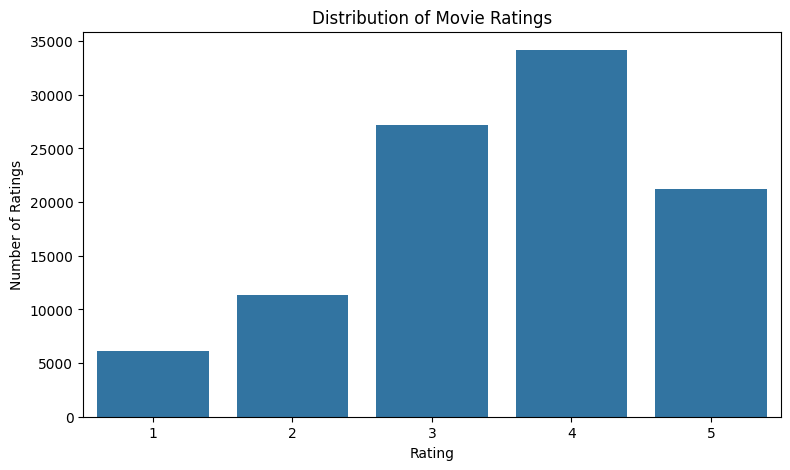

In [9]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="rating")

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")

plt.show()

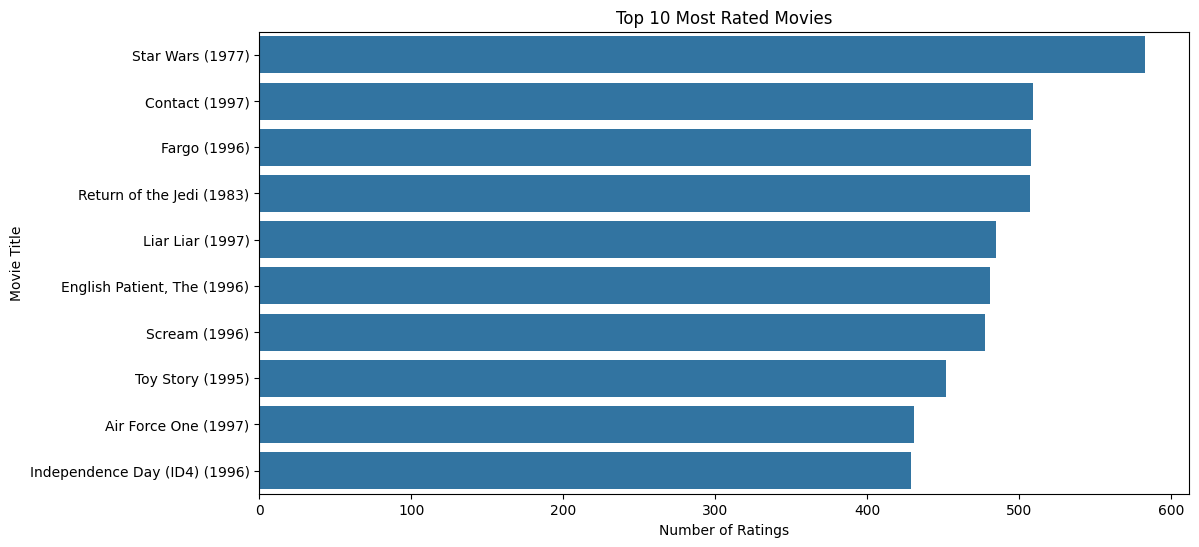

In [32]:
top_movies = (
    df.groupby("title")["rating"]
    .count()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_movies.values, y=top_movies.index)

plt.title("Top 10 Most Rated Movies")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie Title")

plt.show()

In [33]:
df = df[["user_id", "movie_id", "rating", "title"]]

df.head()

,user_id,movie_id,rating,title
0,196,242,3,Kolya (1996)
1,186,302,3,L.A. Confidential (1997)
2,22,377,1,Heavyweights (1994)
3,244,51,2,Legends of the Fall (1994)
4,166,346,1,Jackie Brown (1997)


In [34]:
test_df = df.groupby("user_id", group_keys=False).sample(
    frac=0.2,
    random_state=42
)

train_df = df.drop(test_df.index)

print("Training Data:", train_df.shape)
print("Testing Data:", test_df.shape)

Training Data: (80000, 4)
Testing Data: (20000, 4)


In [35]:
user_item_matrix = train_df.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

print("User-Item Matrix Shape:", user_item_matrix.shape)

user_item_matrix.head()

User-Item Matrix Shape: (943, 1651)


movie_id  1     2     3     4     5     6     7     8     9     10    11    \
user_id                                                                      
1          5.0   NaN   4.0   NaN   3.0   5.0   4.0   1.0   5.0   3.0   2.0   
2          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   2.0   NaN   
3          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
4          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   4.0   
5          4.0   3.0   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   

movie_id  12    13    14    15    16    17    18    19    20    21    22    \
user_id                                                                      
1          5.0   5.0   5.0   5.0   5.0   NaN   4.0   5.0   4.0   1.0   4.0   
2          NaN   NaN   4.0   NaN   NaN   NaN   NaN   3.0   NaN   NaN   NaN   
3          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
4          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
5          NaN   NaN   NaN   NaN   NaN   4.0   NaN   NaN   NaN   3.0   NaN   

movie_id  23    24    25    26    27    28    29    30    31    32    33    \
user_id                                                                      
1          NaN   NaN   NaN   NaN   2.0   NaN   1.0   3.0   NaN   5.0   4.0   
2          NaN   NaN   4.0   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
3          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
4          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
5          NaN   4.0   3.0   NaN   NaN   NaN   4.0   NaN   NaN   NaN   NaN   

movie_id  34    35    36    37    38    39    40    41    42    43    44    \
user_id                                                                      
1          2.0   NaN   NaN   NaN   NaN   NaN   3.0   2.0   5.0   4.0   NaN   
2          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
3          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
4          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
5          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   5.0   NaN   NaN   

movie_id  45    46    47    48    49    50    51    52    53    54    55    \
user_id                                                                      
1          5.0   4.0   4.0   5.0   3.0   5.0   4.0   4.0   3.0   3.0   5.0   
2          NaN   NaN   NaN   NaN   NaN   5.0   NaN   NaN   NaN   NaN   NaN   
3          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
4          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
5          NaN   NaN   NaN   NaN   NaN   4.0   NaN   NaN   NaN   NaN   NaN   

movie_id  56    57    58    59    60    61    62    63    64    65    66    \
user_id                                                                      
1          4.0   5.0   4.0   5.0   5.0   4.0   3.0   2.0   5.0   4.0   4.0   
2          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
3          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
4          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
5          NaN   NaN   NaN   NaN   NaN   NaN   NaN   1.0   NaN   NaN   1.0   

movie_id  67    68    69    70    71    72    73    74    75    76    77    \
user_id                                                                      
1          3.0   4.0   3.0   3.0   3.0   4.0   3.0   NaN   4.0   4.0   4.0   
2          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
3          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
4          NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   
5          NaN   NaN   NaN   4.0   NaN   NaN   NaN   NaN   NaN   NaN   NaN   

movie_id  78    79    80    81    82    83    84    85    86    87    88    \
user_id                                                                      
1          1.0 

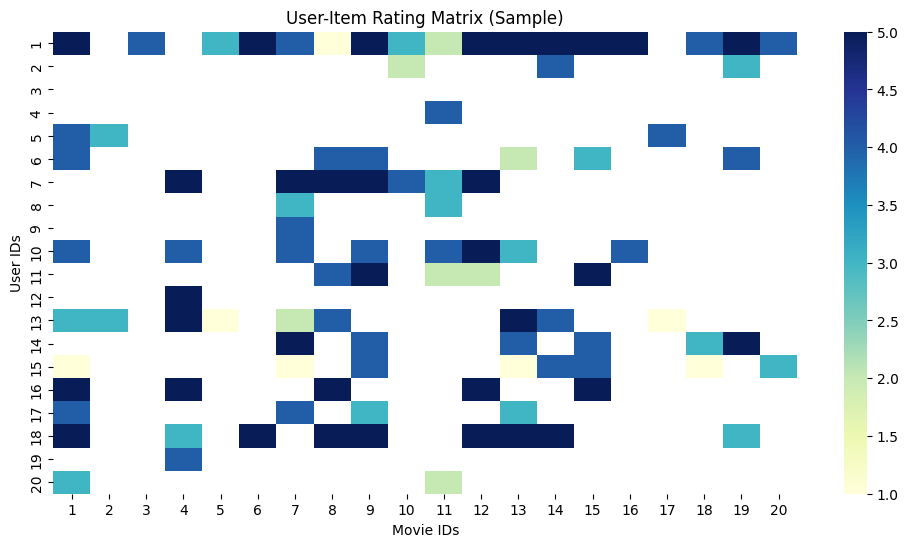

In [36]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    user_item_matrix.iloc[:20, :20],
    cmap="YlGnBu"
)

plt.title("User-Item Rating Matrix (Sample)")
plt.xlabel("Movie IDs")
plt.ylabel("User IDs")

plt.show()

In [37]:
rating_matrix = user_item_matrix.fillna(0).values

rated_mask = (rating_matrix > 0).astype(float)

user_means = np.divide(
    rating_matrix.sum(axis=1),
    rated_mask.sum(axis=1),
    out=np.zeros(rating_matrix.shape[0]),
    where=rated_mask.sum(axis=1) != 0
)

centered_matrix = np.where(
    rated_mask == 1,
    rating_matrix - user_means[:, np.newaxis],
    0
)

print("Mean-centred rating matrix created successfully!")

Mean-centred rating matrix created successfully!


In [38]:
user_similarity = cosine_similarity(centered_matrix)

user_similarity = np.maximum(user_similarity, 0)

np.fill_diagonal(user_similarity, 0)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)

user_similarity_df.head()

user_id,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271,272,273,274,275,276,277,278,279,280,281,282,283,284,285,286,287,288,289,290,291,292,293,294,295,296,297,298,299,300,301,302,303,304,305,306,307,308,309,310,311,312,313,314,315,316,317,318,319,320,321,322,323,324,325,326,327,328,329,330,331,332,333,334,335,336,337,338,339,340,341,342,343,344,345,346,347,348,349,350,351,352,353,354,355,356,357,358,359,360,361,362,363,364,365,366,367,368,369,370,371,372,373,374,375,376,377,378,379,380,381,382,383,384,385,386,387,388,389,390,391,392,393,394,395,396,397,398,399,400,401,402,403,404,405,406,407,408,409,410,411,412,413,414,415,416,417,418,419,420,421,422,423,424,425,426,427,428,429,430,431,432,433,434,435,436,437,438,439,440,441,442,443,444,445,446,447,448,449,450,451,452,453,454,455,456,457,458,459,460,461,462,463,464,465,466,467,468,469,470,471,472,473,474,475,476,477,478,479,480,481,482,483,484,485,486,487,488,489,490,491,492,493,494,495,496,497,498,499,500,501,502,503,504,505,506,507,508,509,510,511,512,513,514,515,516,517,518,519,520,521,522,523,524,525,526,527,528,529,530,531,532,533,534,535,536,537,538,539,540,541,542,543,544,545,546,547,548,549,550,551,552,553,554,555,556,557,558,559,560,561,562,563,564,565,566,567,568,569,570,571,572,573,574,575,576,577,578,579,580,581,582,583,584,585,586,587,588,589,590,591,592,593,594,595,596,597,598,599,600,601,602,603,604,605,606,607,608,609,610,611,612,613,614,615,616,617,618,619,620,621,622,623,624,625,626,627,628,629,630,631,632,633,634,635,636,637,638,639,640,641,642,643,644,645,646,647,648,649,650,651,652,653,654,655,656,657,658,659,660,661,662,663,664,665,666,667,668,669,670,671,672,673,674,675,676,677,678,679,680,681,682,683,684,685,686,687,688,689,690,691,692,693,694,695,696,697,698,699,700,701,702,703,704,705,706,707,708,709,710,711,712,713,714,715,716,717,718,719,720,721,722,723,724,725,726,727,728,729,730,731,732,733,734,735,736,737,738,739,740,741,742,743,744,745,746,747,748,749,750,751,752,753,754,755,756,757,758,759,760,761,762,763,764,765,766,767,768,769,770,771,772,773,774,775,776,777,778,779,780,781,782,783,784,785,786,787,788,789,790,791,792,793,794,795,796,797,798,799,800,801,802,803,804,805,806,807,808,809,810,811,812,813,814,815,816,817,818,819,820,821,822,823,824,825,826,827,828,829,830,831,832,833,834,835,836,837,838,839,840,841,842,843,844,845,846,847,848,849,850,851,852,853,854,855,856,857,858,859,860,861,862,863,864,865,866,867,868,869,870,871,872,873,874,875,876,877,878,879,880,881,882,883,884,885,886,887,888,889,890,891,892,893,894,895,896,897,898,899,900,901,902,903,904,905,906,907,908,909,910,911,912,913,914,915,916,917,918,919,920,921,922,923,924,925,926,927,928,929,930,931,932,933,934,935,936,937,938,939,940,941,942,943
user_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,

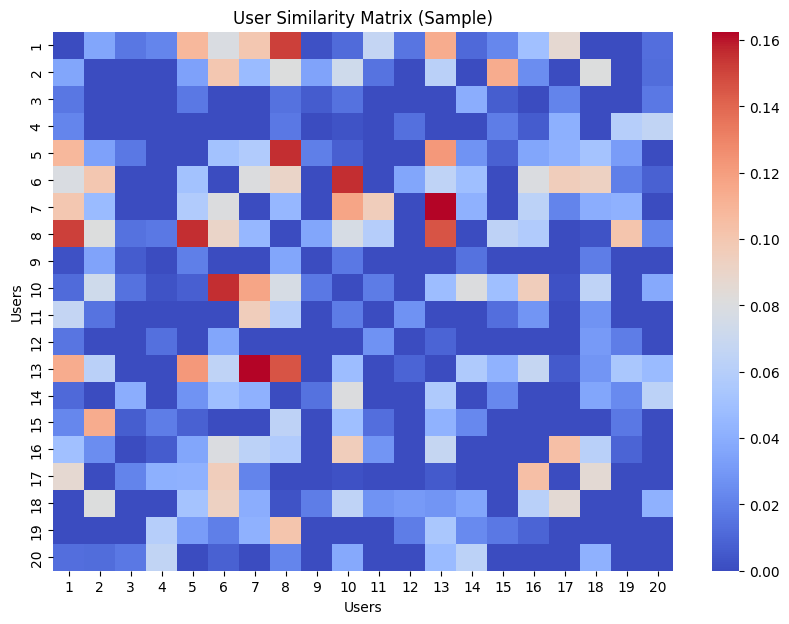

In [39]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    user_similarity_df.iloc[:20, :20],
    cmap="coolwarm"
)

plt.title("User Similarity Matrix (Sample)")
plt.xlabel("Users")
plt.ylabel("Users")

plt.show()

In [40]:
similarity_matrix = user_similarity.copy()

n_neighbors = 50

for i in range(similarity_matrix.shape[0]):
    top_neighbors = np.argsort(similarity_matrix[i])[:-n_neighbors]
    similarity_matrix[i, top_neighbors] = 0

print("Selected the 50 most similar users.")

Selected the 50 most similar users.


In [41]:
weighted_ratings = similarity_matrix @ centered_matrix

similarity_weights = similarity_matrix @ rated_mask

predicted_ratings = np.divide(
    weighted_ratings,
    similarity_weights,
    out=np.zeros_like(weighted_ratings),
    where=similarity_weights != 0
)

predicted_ratings += user_means[:, np.newaxis]

predicted_ratings = np.clip(predicted_ratings, 1, 5)

predicted_ratings_df = pd.DataFrame(
    predicted_ratings,
    index=user_item_matrix.index,
    columns=user_item_matrix.columns
)

predicted_ratings_df.head()

movie_id      1         2         3         4         5         6     \
user_id                                                                
1         4.170547  3.628282  3.163420  4.028687  3.049792  3.432900   
2         4.087756  3.884082  2.479121  2.709214  3.662810  3.985425   
3         3.185978  2.930233  2.392601  2.930233  2.930233  2.930233   
4         4.796481  4.106487  4.156126  4.431174  3.846093  3.204311   
5         3.412218  2.871724  2.113086  3.375464  2.765167  2.242231   

movie_id      7         8         9         10        11        12    \
user_id                                                                
1         3.936668  3.605842  4.309524  4.064489  4.305548  4.777013   
2         3.738842  2.883119  4.315330  2.616439  4.092585  4.633503   
3         2.767566  2.930233  3.057913  2.930233  4.310514  3.614200   
4         4.481164  5.000000  4.219483  4.315789  3.515904  5.000000   
5         3.512533  3.431099  3.520747  3.648909  3.337965  4.054642   

movie_id      13        14        15        16        17        18    \
user_id                                                                
1         3.712053  4.391497  4.251357  3.823860  3.493817  3.743509   
2         3.858185  4.663570  3.652004  3.662377  3.680000  3.680000   
3         2.670134  3.618154  3.382464  2.930233  2.930233  2.930233   
4         5.000000  4.650100  4.952220  4.156126  1.822832  4.315789   
5         2.730297  3.380779  2.832236  2.996292  2.298065  2.942857   

movie_id      19        20        21        22        23        24    \
user_id                                                                
1         3.650974  3.748515  2.979306  4.344489  4.639465  3.695862   
2         4.053535  3.770426  2.962847  3.284464  4.075573  3.216892   
3         3.638310  2.930233  2.930233  3.187995  2.888224  3.619888   
4         5.000000  4.792767  4.338447  5.000000  4.792767  4.228192   
5         3.213524  3.897812  2.762935  4.035203  3.710316  3.172491   

movie_id      25        26        27        28        29        30    \
user_id                                                                
1         3.460751  3.849122  3.251697  4.201598  2.329770  3.960976   
2         3.868944  3.451930  3.680000  4.158247  3.680000  3.680000   
3         3.087467  2.930233  2.930233  4.340975  2.930233  2.867733   
4         4.786784  4.315789  3.675823  4.340749  2.716847  4.315789   
5         3.096795  3.282845  2.722658  3.620489  2.082758  2.849755   

movie_id      31        32        33        34        35        36    \
user_id                                                                
1         3.914330  4.188592  3.490726  2.005386  3.642202  3.005386   
2         3.214483  3.982092  4.084762  3.680000  3.680000  3.680000   
3         2.930233  2.930233  2.930233  2.930233  2.930233  2.930233   
4         4.019136  5.000000  4.102851  4.315789  4.315789  4.315789   
5         3.036410  3.670891  3.132133  1.452519  2.942857  1.217549   

movie_id      37        38        39        40        41        42    \
user_id                                                                
1         3.268632  2.594161  3.248620  2.601972  2.514251  4.370451   
2         3.680000  3.680000  2.084762  3.680000  3.680000  3.874884   
3         2.930233  2.930233  2.930233  2.930233  2.930233  3.805575   
4         4.106487  2.750700  2.241917  4.315789  4.315789  5.000000   
5         2.244039  2.304018  2.428302  2.565081  2.597669  3.757349   

movie_id      43        44        45        46        47        48    \
user_id                                                                
1         3.069384  3.496035  4.479365  4.303619  4.057166  4.275182   
2         3.680000  3.884082  3.548892  3.680000  4.084762  4.468136   
3         2.930233  2.930233  4.122540  2.930233  2.930233  3.875406   
4         3.431174  3.171954  5.000000  4.315789  5.000000  4.315789   
5         1.980069  1.973638  3.2

In [42]:
def recommend_movies(user_id, n_recommendations=10):

    if user_id not in user_item_matrix.index:
        return "User ID not found!"

    user_predictions = predicted_ratings_df.loc[user_id]

    watched_movies = user_item_matrix.loc[user_id]

    user_index = user_item_matrix.index.get_loc(user_id)

    movie_support = similarity_weights[user_index]

    unseen_movies = user_predictions[
        (watched_movies.isna()) &
        (movie_support > 0)
    ]

    top_movies = unseen_movies.sort_values(
        ascending=False
    ).head(n_recommendations)

    recommendations = pd.DataFrame({
        "movie_id": top_movies.index,
        "predicted_rating": top_movies.values
    })

    recommendations = recommendations.merge(
        movies,
        on="movie_id"
    )

    return recommendations[
        ["movie_id", "title", "predicted_rating"]
    ]

In [43]:
user_id = 1

recommendations = recommend_movies(
    user_id,
    n_recommendations=10
)

print("Recommended Movies for User:", user_id)

recommendations

Recommended Movies for User: 1


,movie_id,title,predicted_rating
0,675,"Nosferatu (Nosferatu, eine Symphonie des Graue...",5.0
1,1211,Blue Sky (1994),5.0
2,1193,Before the Rain (Pred dozhdot) (1994),5.0
3,1160,Love! Valour! Compassion! (1997),5.0
4,1629,Nico Icon (1995),5.0
5,1495,Flirt (1995),5.0
6,968,"Inspector General, The (1949)",5.0
7,1007,Waiting for Guffman (1996),5.0
8,1367,Faust (1994),5.0
9,1589,Schizopolis (1996),5.0


In [45]:
def precision_at_k(actual_movies, recommended_movies, k=10):

    recommended_movies = recommended_movies[:k]

    relevant_movies = set(actual_movies)

    hits = sum(
        movie in relevant_movies
        for movie in recommended_movies
    )

    return hits / k

In [46]:
precision_scores = []

test_users = test_df["user_id"].unique()

for user_id in test_users:

    actual_movies = test_df[
        (test_df["user_id"] == user_id) &
        (test_df["rating"] >= 4)
    ]["movie_id"].tolist()

    if len(actual_movies) == 0:
        continue

    recommendations = recommend_movies(
        user_id,
        n_recommendations=10
    )

    recommended_movies = recommendations["movie_id"].tolist()

    score = precision_at_k(
        actual_movies,
        recommended_movies,
        k=10
    )

    precision_scores.append(score)

average_precision = np.mean(precision_scores)

print("Average Precision@10:", average_precision)
print("Precision Percentage:", average_precision * 100, "%")
print("Users Evaluated:", len(precision_scores))

Average Precision@10: 0.006545064377682404
Precision Percentage: 0.6545064377682405 %
Users Evaluated: 932


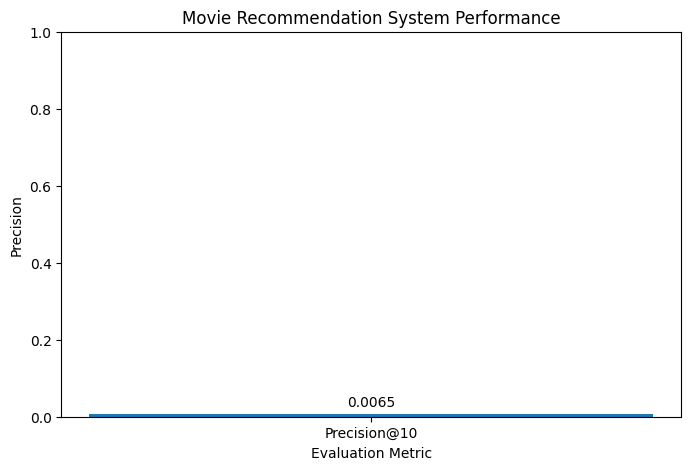

In [47]:
plt.figure(figsize=(8, 5))

plt.bar(["Precision@10"], [average_precision], width=0.4)

plt.title("Movie Recommendation System Performance")
plt.xlabel("Evaluation Metric")
plt.ylabel("Precision")

plt.ylim(0, 1)

plt.text(
    0,
    average_precision + 0.02,
    f"{average_precision:.4f}",
    ha="center"
)

plt.show()

In [48]:
user_id = 10

final_recommendations = recommend_movies(
    user_id,
    n_recommendations=10
)

print("Top 10 Movie Recommendations for User", user_id)

final_recommendations

Top 10 Movie Recommendations for User 10


,movie_id,title,predicted_rating
0,1240,Ghost in the Shell (Kokaku kidotai) (1995),5.0
1,1194,Once Were Warriors (1994),5.0
2,1144,"Quiet Room, The (1996)",5.0
3,1193,Before the Rain (Pred dozhdot) (1994),5.0
4,1268,Bitter Moon (1992),5.0
5,641,Paths of Glory (1957),5.0
6,626,So Dear to My Heart (1949),5.0
7,574,Boxing Helena (1993),5.0
8,593,Stalingrad (1993),5.0
9,592,True Crime (1995),5.0


In [49]:
final_recommendations.to_csv(
    "movie_recommendations.csv",
    index=False
)

print("Recommendations saved successfully!")

Recommendations saved successfully!
